# E4 — Ablation study on the frozen main model


**Rules from the plan (§0, §4).**
- Validation only. The shared loader tokenises the test split, but this notebook never loads or evaluates it, and it is not used for selection.
- Each training ablation changes **one** setting; everything else equals the frozen E2 configuration.
- Every result uses seeds 4012, 4013, 4014 and is reported as mean ± s.d., with paired McNemar tests per seed.
- A2-a re-evaluates the trained checkpoints without retraining.


## 1 · Setup

Mount Drive and check the GPU. Update the shared repository (branch `baselines`) and check that it is clean. Every run records the commit it actually used.


In [1]:
import json, os, subprocess, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentencepiece'], check=True)

from google.colab import drive
drive.mount('/content/drive')

import torch
assert torch.cuda.is_available(), 'Runtime > Change runtime type > T4 GPU, then rerun.'
print(torch.cuda.get_device_name(0))

REPO = Path('/content/repo')
if not (REPO / '.git').exists():
    subprocess.run(['git', 'clone', '-q', '-b', 'baselines',
                    'https://github.com/RayYouDS/cits4012-NLP-project.git', str(REPO)], check=True)

def git(*args):
    return subprocess.check_output(['git', '-C', str(REPO), *args], text=True).strip()

# An old clone can sit on another branch, an older commit, or with local edits.
assert git('rev-parse', '--abbrev-ref', 'HEAD') == 'baselines', 'Delete /content/repo and rerun.'
subprocess.run(['git', '-C', str(REPO), 'fetch', '-q', 'origin', 'baselines'], check=True)
E4_COMMIT = git('rev-parse', 'HEAD')
assert E4_COMMIT == git('rev-parse', 'FETCH_HEAD'), 'Clone is not at origin/baselines. Delete /content/repo and rerun.'
assert git('status', '--porcelain', '--untracked-files=no') == '', 'Tracked files in /content/repo are edited. Delete it and rerun.'
print('running code from baselines commit', E4_COMMIT[:9])


Mounted at /content/drive
Tesla T4
running code from baselines commit 2fa9820cc


## 2 · The frozen E2 configuration

These are the settings every ablation inherits. Only the three seeds and the E2 folder are fixed here; everything else comes from `config.json`.


In [2]:
E2_DIR = Path('/content/drive/MyDrive/cits4012/e2_full_300/final_3seed')
FROZEN = json.loads((E2_DIR / 'config.json').read_text(encoding='utf-8'))

assert FROZEN['models'] == ['transformer']
assert FROZEN['max_epochs'] == 300
assert sorted(FROZEN['seeds']) == [4012, 4013, 4014]
assert len(FROZEN['learning_rates']) == 1
assert FROZEN['dropout_rate'] != 0.0, 'Main model has dropout 0, so A3 needs a different comparison.'

SEEDS = [4012, 4013, 4014]
LR = FROZEN['learning_rates'][0]
EXPECTED_VALID_ROWS = 1606   # validation split size (plan §0)
E2_COMMIT = FROZEN['_commit']

pd.Series({k: FROZEN[k] for k in ['optimizer', 'learning_rates', 'weight_decay', 'dropout_rate',
                                  'num_layers', 'num_heads', 'pooling', 'enable_pos_emb',
                                  'batch_size', 'max_epochs', 'patience']}, name='frozen E2')


,frozen E2
optimizer,adamw
learning_rates,[0.0009]
weight_decay,0.01
dropout_rate,0.3
num_layers,2
num_heads,4
pooling,cls
enable_pos_emb,True
batch_size,512
max_epochs,300


**Provenance check.** E2 ran on commit `E2_COMMIT`. This notebook runs on `E4_COMMIT`. The comparison is valid only if the code the model depends on is unchanged between the two, so this check fails loudly if it is not. Changes to other files (docs, baseline scripts) are allowed.


In [3]:
E2_PATHS = ['scripts/training/', 'scripts/models/', 'scripts/data_loader/',
            'scripts/evaluation/', 'scripts/tokenizer/', 'datasets/']
changed = git('diff', '--name-only', E2_COMMIT, E4_COMMIT, '--', *E2_PATHS).split()
assert not changed, f'Code used by E2 changed between {E2_COMMIT[:9]} and {E4_COMMIT[:9]}: {changed}'
untracked = git('ls-files', '--others', '--exclude-standard', '--', *E2_PATHS)
assert untracked == '', f'Untracked files in code used by E2: {untracked}'
print(f'E2 code unchanged: {E2_COMMIT[:9]} -> {E4_COMMIT[:9]}')


E2 code unchanged: d0268525b -> 2fa9820cc


**Reference: the E2 result for the frozen configuration.** These are the numbers every ablation is compared against.


In [4]:
e2 = pd.read_csv(E2_DIR / 'm3_summary.csv')
print(e2[['seed', 'valid_accuracy', 'best_epoch', 'gap_at_best']].to_string(index=False))
print(f"mean {e2.valid_accuracy.mean():.4f}, s.d. {e2.valid_accuracy.std():.4f}")


 seed  valid_accuracy  best_epoch  gap_at_best
 4012        0.599626         213     0.289539
 4013        0.597758         179     0.267746
 4014        0.584682         164     0.267123
mean 0.5940, s.d. 0.0081


## 3 · Choose the ablations

Each entry changes exactly one setting. The Transformer main model has 4 heads, CLS pooling and positional encoding on, so:
- `a1_no_position` removes positional encoding (A1′-a).
- `a1_one_head` changes 4 heads to 1 head (A1′-b).
- `a1_mean_pooling` changes CLS pooling to mean pooling (A1′-c).
- `a3_no_dropout` changes dropout 0.3 to 0 (A3).

**Team decision:** `CHOSEN` is set to `a1_no_position` (A1′-a, position information) and `a1_one_head` (A1′-b, one head vs four). `a1_mean_pooling` is not run. The notebook still checks that `CHOSEN` has one or two valid, non-duplicate rows. Record the choice and the reason in the report.


In [5]:
ABLATIONS = {
    'a1_no_position':  {'enable_pos_emb': False},
    'a1_one_head':     {'num_heads': 1},
    'a1_mean_pooling': {'pooling': 'mean'},
    'a3_no_dropout':   {'dropout_rate': 0.0},
}

CHOSEN = ['a1_no_position', 'a1_one_head']   # team decision: A1'-a and A1'-b
assert 1 <= len(CHOSEN) <= 2 and all(c in ('a1_no_position', 'a1_one_head', 'a1_mean_pooling') for c in CHOSEN), \
    'Set CHOSEN to one or two A1′ rows (team decision) before running.'
assert len(CHOSEN) == len(set(CHOSEN)), 'CHOSEN lists the same ablation twice.'
RUN_NAMES = CHOSEN + ['a3_no_dropout']

E4_DIR = Path('/content/drive/MyDrive/cits4012/e4_full')
E4_DIR.mkdir(parents=True, exist_ok=True)

def make_config(name):
    change = ABLATIONS[name]
    # One variable per ablation: the rule is on the declared change itself.
    assert len(change) == 1, f'{name} changes {len(change)} settings; an ablation changes exactly one.'
    cfg = {**FROZEN, **change, 'seeds': SEEDS, 'max_epochs': 300,
           'output_dir': str(E4_DIR / name), '_ablation': name, '_changes': change,
           '_base_commit': E2_COMMIT, '_commit': E4_COMMIT}
    cfg.pop('_from', None)
    # Nothing else may differ from the frozen configuration.
    differs = [k for k in FROZEN if not k.startswith('_') and k not in ('output_dir', 'seeds', 'max_epochs')
               and FROZEN[k] != cfg.get(k)]
    assert differs == list(change), f'{name} changes {differs}, expected {list(change)}'
    return cfg

for name in RUN_NAMES:
    cfg = make_config(name)
    print(f"{name:16s} changes {cfg['_changes']}")


a1_no_position   changes {'enable_pos_emb': False}
a1_one_head      changes {'num_heads': 1}
a3_no_dropout    changes {'dropout_rate': 0.0}


## 4 · Train the ablations

Each ablation is 3 seeds × 300 epochs, about 16 minutes per run on a T4, so about 50 minutes per ablation. Colab can disconnect mid-run, and a run that dies is not resumed. If a folder has files but no `m3_summary.csv`, delete that folder and rerun the cell.

A finished folder is **not** reused blindly. The checks below confirm that its configuration is this ablation on this E2 base, that the code it depends on has not changed since it ran, that all three seeds are complete, and that every history ends at epoch 300. Changes in other files (reports, figures, docs) do not force a rerun.


In [6]:
def final_epoch(folder, seed):
    h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
    last = h.iloc[-1]
    assert int(last['epoch']) == 300, f'{folder.name} seed {seed} ended at epoch {int(last["epoch"])}'
    return {'gap_at_end': float(last['train_eval_accuracy'] - last['valid_accuracy']),
            'valid_loss_at_end': float(last['valid_loss'])}

def check_training_folder(name):
    out = E4_DIR / name
    cfg = make_config(name)
    saved = json.loads((out / 'config.json').read_text(encoding='utf-8'))

    # 1. The saved configuration is this ablation, built on this E2 base.
    assert saved.get('_ablation') == name, f'{name}: saved _ablation is {saved.get("_ablation")}'
    assert saved.get('_base_commit') == E2_COMMIT, f'{name}: saved _base_commit is not the E2 commit'
    assert saved.get('_changes') == ABLATIONS[name], f'{name}: saved _changes differ'
    for k in cfg:
        if not k.startswith('_') and k != 'output_dir' and saved.get(k) != cfg[k]:
            raise RuntimeError(f'{name}: saved config differs on {k}: {saved.get(k)} vs {cfg[k]}')

    # 2. Code the experiment depends on has not changed since it ran.
    saved_commit = saved.get('_commit')
    if not saved_commit:
        raise RuntimeError(f'{name}: saved config has no _commit')
    touched = git('diff', '--name-only', saved_commit, E4_COMMIT, '--', *E2_PATHS).split()
    if touched:
        raise RuntimeError(f'{name}: code used by this experiment changed: {touched}')
    if saved_commit != E4_COMMIT:
        print(name, 'reused: commit differs, but experiment-dependent code is unchanged')

    # 3. Summary: right model, learning rate, budget, and all three seeds.
    summary = pd.read_csv(out / 'm3_summary.csv')
    assert set(summary['model']) == {'transformer'}, f'{name}: models {set(summary["model"])}'
    assert all(abs(x - LR) < 1e-12 for x in summary['learning_rate']), f'{name}: learning rates differ'
    assert set(summary['epochs_run']) == {300}, f'{name}: epochs_run {set(summary["epochs_run"])}'
    if sorted(summary['seed'].astype(int)) != SEEDS:
        raise RuntimeError(f'{name}: summary seeds are {sorted(summary["seed"])}, expected {SEEDS}')

    # 4. Every seed has history, validation predictions and the checkpoint;
    #    the history ends at epoch 300; the predictions cover the validation split.
    for seed in SEEDS:
        base = f'm3_transformer_lr{LR:g}_seed{seed}'
        for f in (f'{base}_history.csv', f'{base}_val_predictions.csv', f'{base}_best.pt'):
            if not (out / f).exists():
                raise RuntimeError(f'{name}: missing {f}')
        if len(pd.read_csv(out / f'{base}_val_predictions.csv')) != EXPECTED_VALID_ROWS:
            raise RuntimeError(f'{name} seed {seed}: predictions do not cover the validation split')
        final_epoch(out, seed)
    return True

def train(name):
    cfg = make_config(name)
    out = E4_DIR / name
    if (out / 'm3_summary.csv').exists():
        check_training_folder(name)
        print(name, 'already finished and verified')
        return
    partial = [p.name for p in out.glob('*') if p.name != 'config.json'] if out.exists() else []
    if partial:
        raise RuntimeError(f'{out} has partial files {partial[:4]} but no summary. Delete it and rerun.')
    out.mkdir(parents=True, exist_ok=True)
    cfg_path = out / 'config.json'
    cfg_path.write_text(json.dumps(cfg, indent=2), encoding='utf-8')
    subprocess.run([sys.executable, '-m', 'scripts.training.run_m3', '--config', str(cfg_path)],
                   cwd=REPO, check=True)
    check_training_folder(name)
    print(name, 'done and verified')

for name in RUN_NAMES:
    train(name)


a1_no_position already finished and verified
a1_one_head already finished and verified
a3_no_dropout already finished and verified


## 5 · A2-a: remove the goal at evaluation time

The frozen checkpoints were trained **with** the goal. Here they are scored on validation input `[CLS] [SEP] solution [EOS]` (goal removed). No retraining. The model never saw this input format during training, so a drop in accuracy measures reliance on the goal. It is not a clean measure of what a model trained without goals would do (that is A2-b).


In [7]:
A2A_DIR = E4_DIR / 'a2a_no_goal'

def check_a2a(seed):
    out = A2A_DIR / f'seed{seed}'
    m = json.loads((out / 'metrics.json').read_text(encoding='utf-8'))
    assert m['split'] == 'valid', f'seed {seed}: split is {m["split"]}'
    assert m['include_goal'] is False, f'seed {seed}: goal was not removed'
    assert m['n'] == EXPECTED_VALID_ROWS, f'seed {seed}: n = {m["n"]}'
    assert Path(m['checkpoint']).name == f'm3_transformer_lr{LR:g}_seed{seed}_best.pt', \
        f'seed {seed}: wrong checkpoint {m["checkpoint"]}'
    pred = pd.read_csv(out / 'valid_predictions.csv')
    assert {'row_id', 'label', 'pred', 'correct'}.issubset(pred.columns), 'prediction columns missing'
    assert len(pred) == EXPECTED_VALID_ROWS, f'seed {seed}: {len(pred)} prediction rows'
    assert pred['row_id'].is_unique, f'seed {seed}: duplicate row_id'
    assert sorted(pred['row_id'].astype(int)) == list(range(EXPECTED_VALID_ROWS)), \
        f'seed {seed}: row_id does not cover the validation split'
    return True

for seed in SEEDS:
    out = A2A_DIR / f'seed{seed}'
    if (out / 'valid_predictions.csv').exists():
        check_a2a(seed)
        print('seed', seed, 'already evaluated and verified')
        continue
    ckpt = E2_DIR / f'm3_transformer_lr{LR:g}_seed{seed}_best.pt'
    assert ckpt.exists(), f'missing checkpoint {ckpt}'
    subprocess.run([sys.executable, '-m', 'scripts.evaluation.evaluate_checkpoint',
                    '--config', str(E2_DIR / 'config.json'), '--model', 'transformer',
                    '--checkpoint', str(ckpt), '--split', 'valid',
                    '--output-dir', str(out), '--no-include-goal'],
                   cwd=REPO, check=True)
    check_a2a(seed)


seed 4012 already evaluated and verified
seed 4013 already evaluated and verified
seed 4014 already evaluated and verified


## 6 · Results

**Table 1.** Mean ± s.d. over three seeds. Two overfitting gaps are shown: at the best epoch (where the model was selected), and at the final epoch 300 (the plan's A3 check). The gap is the training-evaluation accuracy minus the validation accuracy. The final validation loss is shown as well.


In [8]:
def run_summary(name, folder):
    s = pd.read_csv(folder / 'm3_summary.csv')
    s['experiment'] = name
    ends = pd.DataFrame([{'seed': seed, **final_epoch(folder, seed)} for seed in SEEDS])
    return s.merge(ends, on='seed')

frames = [run_summary('main (E2)', E2_DIR)]
frames += [run_summary(n, E4_DIR / n) for n in RUN_NAMES]
allruns = pd.concat(frames, ignore_index=True)

table1 = allruns.groupby('experiment', sort=False).agg(
    seeds=('seed', 'nunique'),
    valid_mean=('valid_accuracy', 'mean'),
    valid_sd=('valid_accuracy', 'std'),
    gap_at_best_mean=('gap_at_best', 'mean'),
    gap_at_best_sd=('gap_at_best', 'std'),
    gap_at_end_mean=('gap_at_end', 'mean'),
    gap_at_end_sd=('gap_at_end', 'std'),
    valid_loss_at_end_mean=('valid_loss_at_end', 'mean'),
    best_epoch_mean=('best_epoch', 'mean'),
).reset_index().round(4)
table1.to_csv(E4_DIR / 'e4_table1.csv', index=False)
table1


,experiment,seeds,valid_mean,valid_sd,gap_at_best_mean,gap_at_best_sd,gap_at_end_mean,gap_at_end_sd,valid_loss_at_end_mean,best_epoch_mean
0,main (E2),3,0.5940,0.0081,0.2748,0.0128,0.3474,0.0047,1.0513,185.3333
1,a1_no_position,3,0.5969,0.0050,0.2644,0.0856,0.3447,0.0158,0.9469,183.3333
2,a1_one_head,3,0.5863,0.0016,0.2217,0.0462,0.2798,0.0069,0.9151,186.6667
3,a3_no_dropout,3,0.5627,0.0121,0.2549,0.1865,0.4585,0.0212,6.8791,10.6667


**Table 2.** Paired comparison with the main model, seed by seed. The McNemar test uses the same validation questions for both models. Delta is ablation minus main, so a negative number means the ablation is worse.


In [9]:
os.chdir(REPO)
sys.path.insert(0, str(REPO))
from scripts.evaluation.evaluate import mcnemar_test

def as_bool(series):
    return series.astype(str).str.lower().isin(['true', '1']).to_numpy()

def load_correct(path):
    df = pd.read_csv(path)
    return df[['row_id', 'correct']]

def paired(main_df, other_df):
    m = main_df.merge(other_df, on='row_id', suffixes=('_main', '_other'))
    assert len(m) == len(main_df) == len(other_df), 'validation rows do not match'
    a, b = as_bool(m.correct_main), as_bool(m.correct_other)
    res = mcnemar_test(a, b)
    return {'main_acc': a.mean(), 'other_acc': b.mean(), 'delta': b.mean() - a.mean(),
            'only_main': res['only_a'], 'only_other': res['only_b'], 'p_value': res['p_value']}

rows = []
for seed in SEEDS:
    main_df = load_correct(E2_DIR / f'm3_transformer_lr{LR:g}_seed{seed}_val_predictions.csv')
    for name in RUN_NAMES:
        other = load_correct(E4_DIR / name / f'm3_transformer_lr{LR:g}_seed{seed}_val_predictions.csv')
        rows.append({'experiment': name, 'seed': seed, **paired(main_df, other)})
    rows.append({'experiment': 'a2a_no_goal', 'seed': seed, **paired(
        main_df, load_correct(A2A_DIR / f'seed{seed}' / 'valid_predictions.csv'))})

table2_raw = pd.DataFrame(rows)

a2_summary = (
    table2_raw.query("experiment == 'a2a_no_goal'")
    [['other_acc', 'delta']]
    .agg(['mean', 'std'])
).round(4)
print('A2-a across three seeds (mean and sample s.d.):')
display(a2_summary)
a2_summary.to_csv(E4_DIR / 'e4_a2a_summary.csv')

table2 = table2_raw.round(4)
table2.to_csv(E4_DIR / 'e4_table2.csv', index=False)
table2


A2-a across three seeds (mean and sample s.d.):


,other_acc,delta
mean,0.5702,-0.0239
std,0.0051,0.0072


,experiment,seed,main_acc,other_acc,delta,only_main,only_other,p_value
0,a1_no_position,4012,0.5996,0.6021,0.0025,202,206,0.8819
1,a1_one_head,4012,0.5996,0.5847,-0.0149,207,183,0.2442
2,a3_no_dropout,4012,0.5996,0.5766,-0.0230,323,286,0.1446
3,a2a_no_goal,4012,0.5996,0.5760,-0.0237,170,132,0.0332
4,a1_no_position,4013,0.5978,0.5965,-0.0012,187,185,0.9587
5,a1_one_head,4013,0.5978,0.5866,-0.0112,162,144,0.3311
6,a3_no_dropout,4013,0.5978,0.5548,-0.0430,338,269,0.0058
7,a2a_no_goal,4013,0.5978,0.5666,-0.0311,159,109,0.0028
8,a1_no_position,4014,0.5847,0.5922,0.0075,184,196,0.5726
9,a1_one_head,4014,0.5847,0.5878,0.0031,179,184,0.8337


**Graph 1.** Validation loss and overfitting gap per epoch, main model (grey) against A3 with no dropout (orange). Three seeds, one row each.


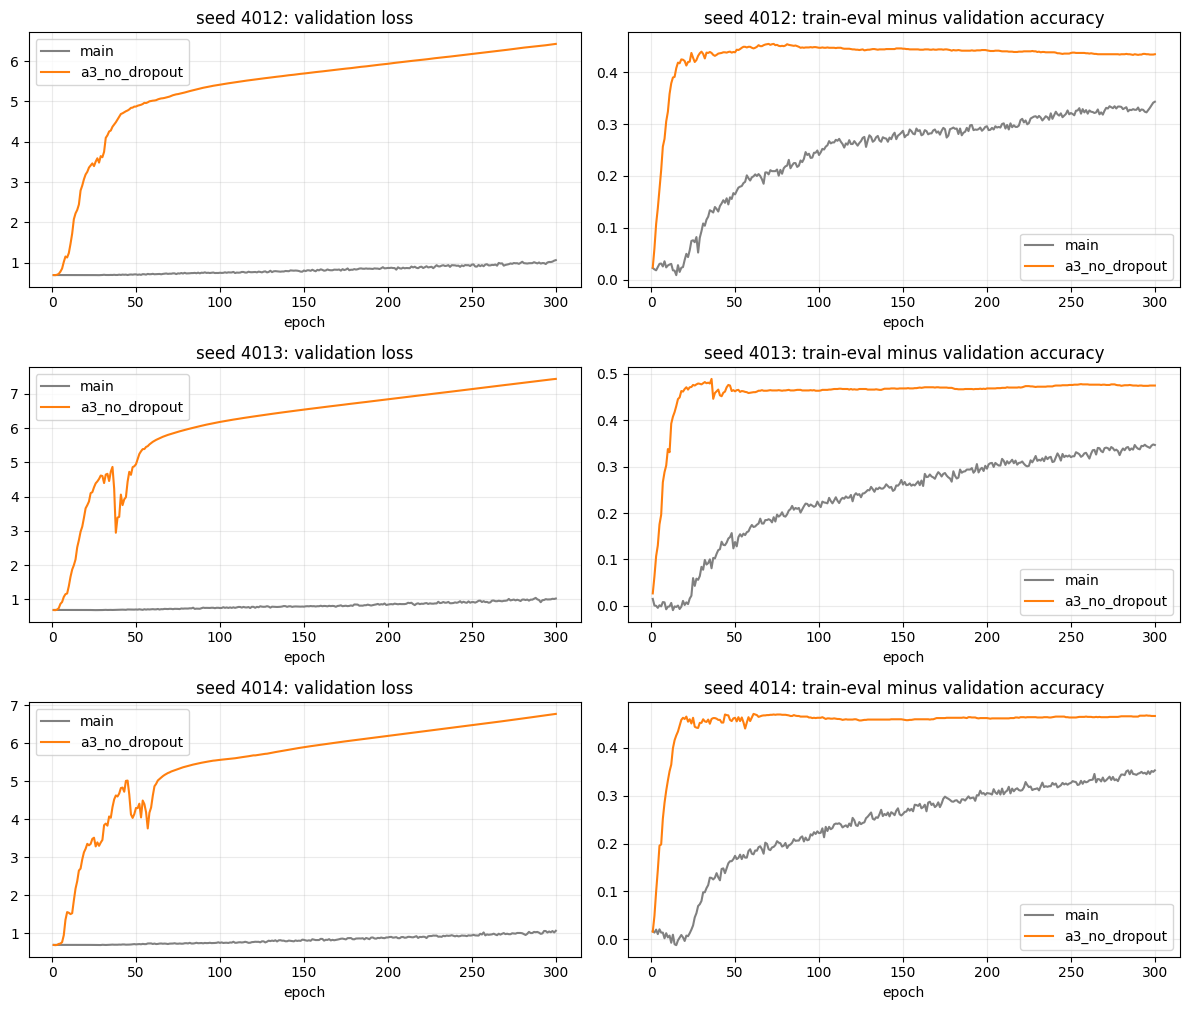

In [10]:
fig, axes = plt.subplots(len(SEEDS), 2, figsize=(12, 3.4 * len(SEEDS)))
for row, seed in enumerate(SEEDS):
    for label, folder, colour in [('main', E2_DIR, 'grey'), ('a3_no_dropout', E4_DIR / 'a3_no_dropout', 'tab:orange')]:
        h = pd.read_csv(folder / f'm3_transformer_lr{LR:g}_seed{seed}_history.csv')
        axes[row, 0].plot(h['epoch'], h['valid_loss'], color=colour, label=label)
        axes[row, 1].plot(h['epoch'], h['train_eval_accuracy'] - h['valid_accuracy'], color=colour, label=label)
    axes[row, 0].set_title(f'seed {seed}: validation loss')
    axes[row, 1].set_title(f'seed {seed}: train-eval minus validation accuracy')
    for ax in axes[row]:
        ax.set_xlabel('epoch'); ax.grid(alpha=0.25); ax.legend()
fig.tight_layout()
fig.savefig(E4_DIR / 'a3_gap_loss.png', dpi=150, bbox_inches='tight')
plt.show()


## 7 · Sample outputs

How many validation questions change correctness when the goal is removed (A2-a), per seed.


In [11]:
for seed in SEEDS:
    main_df = load_correct(E2_DIR / f'm3_transformer_lr{LR:g}_seed{seed}_val_predictions.csv')
    a2a = load_correct(A2A_DIR / f'seed{seed}' / 'valid_predictions.csv')
    m = main_df.merge(a2a, on='row_id', suffixes=('_main', '_a2a'))
    a, b = as_bool(m.correct_main), as_bool(m.correct_a2a)
    print(f'seed {seed}: right with goal, wrong without: {int((a & ~b).sum())}; '
          f'wrong with goal, right without: {int((~a & b).sum())}; '
          f'total changed: {int((a != b).sum())} of {len(m)}')


seed 4012: right with goal, wrong without: 170; wrong with goal, right without: 132; total changed: 302 of 1606
seed 4013: right with goal, wrong without: 159; wrong with goal, right without: 109; total changed: 268 of 1606
seed 4014: right with goal, wrong without: 138; wrong with goal, right without: 111; total changed: 249 of 1606


In [13]:
     import platform
     freeze = subprocess.check_output([sys.executable, '-m', 'pip', 'freeze'], text=True)
     (E4_DIR / 'env_freeze.txt').write_text(freeze, encoding='utf-8')
     env = {'python': platform.python_version(), 'torch': torch.__version__,
            'cuda': torch.version.cuda, 'gpu': torch.cuda.get_device_name(0),
            'repo_commit': E4_COMMIT, 'e2_commit': E2_COMMIT}
     (E4_DIR / 'env.json').write_text(json.dumps(env, indent=2), encoding='utf-8')
     print(env)

{'python': '3.13.15', 'torch': '2.11.0+cu130', 'cuda': '13.0', 'gpu': 'Tesla T4', 'repo_commit': '2fa9820ccd9e0c8833ffbf6ec900c5d7f0f7cd94', 'e2_commit': 'd0268525b83d7af9f5d5b3a684b6ad8dec00d4d7'}
